### ML App (Credit Card Fraud Detection System) Part 2

#### Team members

- Alson Garbuja
- Kapil Bam
- Slok Baniya
- Nishan Parajuli
- Karma Dolma Gurung
- Sishir Kharel

In [1]:
"""
Imports

This cell has all the required imports from the third party libraries like pandas, numpy and sckit-learn (sklearn)
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [2]:
"""
Data pre-processing

This cell contains the data pre-processing and cleaning of the data for the model to be fed
"""

df = pd.read_csv('datasets/creditcard.csv')
df.dropna()

X_reg = df.drop(['Amount', 'Time', 'Class'], axis=1)
y_reg = df['Amount']

X_cls = df.drop(['Class', 'Time'], axis=1)
y_cls = df['Class']

In [3]:
"""
Data splitting

This cell uses the train_test_split function from sklearn package to split the dataset into training and testing sets.

The `stratify = y_cls` argument makes sure the extreme 99% to 1% normal to fraud data distribution in the original dataset is maintained 
in both training and testing splits of the data.
"""

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

In [4]:
"""
Data scaling

This cell holds the code to scale the data with mean of 0 and standard deviation of 1 so that numerically larger data doesnot dominate the
smaller data.
"""

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

scaler_cls = StandardScaler()
X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)

In [6]:
# Cell 5: Part 2 Imports and Feature Selection (L1 Regularization)
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np

print("=== FEATURE SELECTION (L1 Regularization) ===")
# Use L1-penalized LinearSVC to determine essential features
selector = SelectFromModel(LinearSVC(penalty='l1', dual=False, random_state=42, max_iter=2000))
X_train_selected = selector.fit_transform(X_train_cls_scaled, y_train_cls)
X_test_selected = selector.transform(X_test_cls_scaled)

# Retrieve the names of the features that survived the L1 cut
selected_feature_names = selector.get_feature_names_out()

print(f"Features reduced from {X_train_cls_scaled.shape[1]} down to {X_train_selected.shape[1]}.")
print(f"Features kept: {selected_feature_names}\n")

=== FEATURE SELECTION (L1 Regularization) ===
Features reduced from 29 down to 29.
Features kept: ['x0' 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'x7' 'x8' 'x9' 'x10' 'x11' 'x12' 'x13'
 'x14' 'x15' 'x16' 'x17' 'x18' 'x19' 'x20' 'x21' 'x22' 'x23' 'x24' 'x25'
 'x26' 'x27' 'x28']



=== DECISION TREE ===
--- Decision Tree Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.71      0.71      0.71        98

    accuracy                           1.00     56962
   macro avg       0.85      0.86      0.86     56962
weighted avg       1.00      1.00      1.00     56962



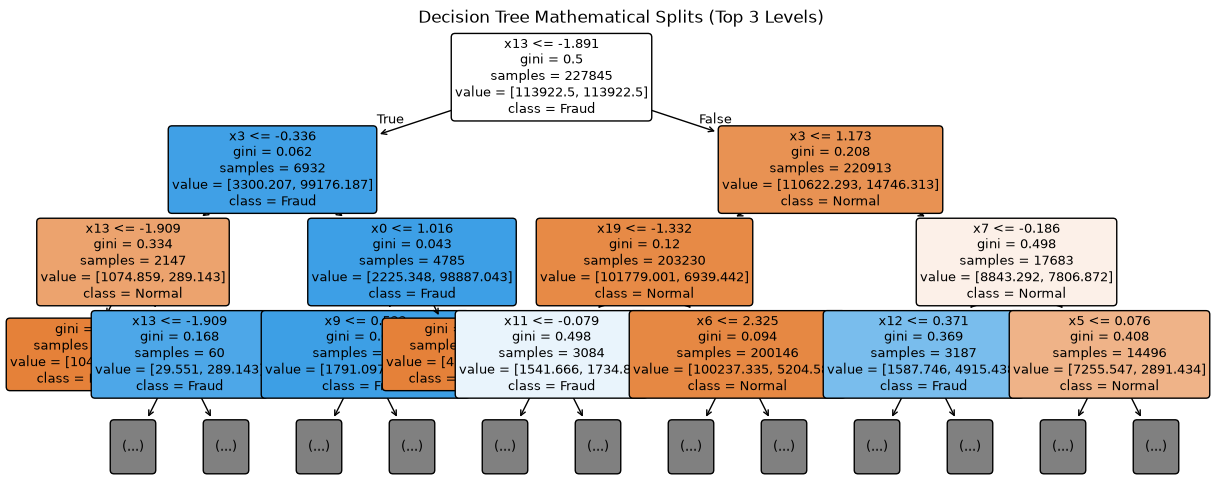

In [7]:
"""
DECISION TREE Model
"""

# Cell 6: Decision Tree Model and Split Visualization
print("=== DECISION TREE ===")

dtree = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dtree.fit(X_train_selected, y_train_cls)
y_pred_dtree = dtree.predict(X_test_selected)

print("--- Decision Tree Report ---")
print(classification_report(y_test_cls, y_pred_dtree))

# DIAGRAM: Visualizing how the Decision Tree calculates its splits
plt.figure(figsize=(15, 6))
plot_tree(
    dtree, 
    max_depth=3, # Limit depth so the graph is readable in the notebook
    feature_names=selected_feature_names, 
    class_names=['Normal', 'Fraud'], 
    filled=True, 
    fontsize=9,
    rounded=True
)
plt.title("Decision Tree Mathematical Splits (Top 3 Levels)")
plt.show()

=== RANDOM FOREST ===
--- Random Forest Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.80      0.85        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



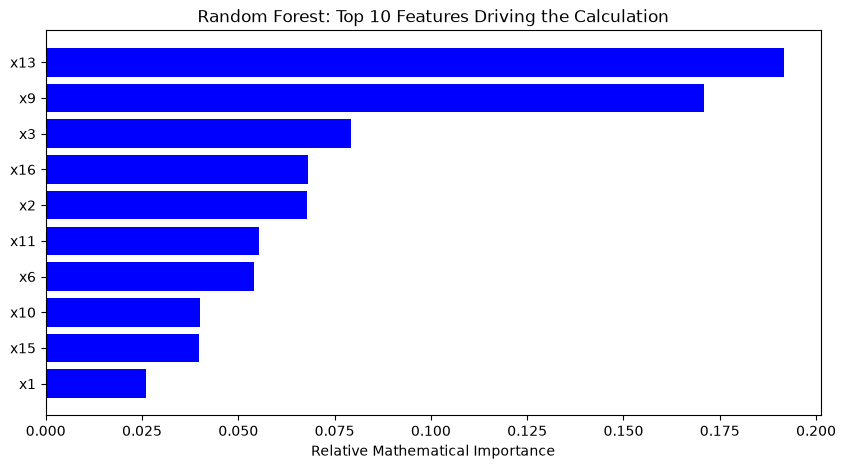

In [8]:
"""
RANDOM FOREST Model
"""
# Cell 7: Random Forest Model and Feature Importance Diagram
print("=== RANDOM FOREST ===")

rf = RandomForestClassifier(n_estimators=20, random_state=42, class_weight='balanced', n_jobs=-1)
rf.fit(X_train_selected, y_train_cls)
y_pred_rf = rf.predict(X_test_selected)

print("--- Random Forest Report ---")
print(classification_report(y_test_cls, y_pred_rf))

# DIAGRAM: Visualizing how the Random Forest weighs features mathematically
importances = rf.feature_importances_
indices = np.argsort(importances)[-10:] # Get the top 10 most important features

plt.figure(figsize=(10, 5))
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [selected_feature_names[i] for i in indices])
plt.xlabel('Relative Mathematical Importance')
plt.title('Random Forest: Top 10 Features Driving the Calculation')
plt.show()

In [9]:
"""
SVM Model
"""
# Cell 8: Support Vector Machine (Subsampled for Performance)
print("=== SUPPORT VECTOR MACHINE ===")

# Subsample to prevent Jupyter memory crashes when calculating distance margins
sample_size = 20000
X_train_sample = X_train_selected[:sample_size]
y_train_sample = y_train_cls[:sample_size]

svm = LinearSVC(class_weight='balanced', random_state=42, max_iter=3000)
svm.fit(X_train_sample, y_train_sample)
y_pred_svm = svm.predict(X_test_selected)

print("--- Support Vector Machine (Subsampled) Report ---")
print(classification_report(y_test_cls, y_pred_svm))

=== SUPPORT VECTOR MACHINE ===
--- Support Vector Machine (Subsampled) Report ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.04      0.85      0.08        98

    accuracy                           0.97     56962
   macro avg       0.52      0.91      0.53     56962
weighted avg       1.00      0.97      0.98     56962



In [10]:
"""
KNN Model
"""
# Cell 9: K-Nearest Neighbors (Subsampled for Performance)
print("=== K-NEAREST NEIGHBORS ===")

# KNN uses the same subsampled data from Cell 8
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_sample, y_train_sample)
y_pred_knn = knn.predict(X_test_selected)

print("--- K-Nearest Neighbors (Subsampled) Report ---")
print(classification_report(y_test_cls, y_pred_knn))

=== K-NEAREST NEIGHBORS ===
--- K-Nearest Neighbors (Subsampled) Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.80      0.73      0.77        98

    accuracy                           1.00     56962
   macro avg       0.90      0.87      0.88     56962
weighted avg       1.00      1.00      1.00     56962



In [11]:
"""
SGD Classifier Model
"""
# Cell 10: SGD Classifier (Optimized L2 Regularization)
print("=== SGD CLASSIFIER (Optimized) ===")

sgd_opt = SGDClassifier(
    loss='hinge', 
    penalty='l2', 
    alpha=0.001, 
    class_weight='balanced', 
    max_iter=2000, 
    random_state=42
)
sgd_opt.fit(X_train_selected, y_train_cls)
y_pred_sgd = sgd_opt.predict(X_test_selected)

print("--- SGD Classifier (Hinge Loss + L2) Report ---")
print(classification_report(y_test_cls, y_pred_sgd))

=== SGD CLASSIFIER (Optimized) ===
--- SGD Classifier (Hinge Loss + L2) Report ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.91      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962

